# Proyecto 01: Retail Intelligence
## A2: Análisis de Rentabilidad y Comportamiento de Compra
**Asignatura:** Tópicos Especiales para la Gestión de Datos  
**Caso:** RetailVenture C.A.  
**Autor:** Daniel Azuaje (Equipo RetailVenture)

---

### Objetivos de la Actividad:
1. **A2.1 Contribución al Margen Bruto:** Identificar segmentos, categorías y canales con mayor/menor aporte al margen total.
2. **A2.2 Customer Lifetime Value (CLV):** Estimar el CLV por segmento e identificar segmentos en declive.
3. **A2.3 Estacionalidad:** Analizar picos, valles y tendencias temporales por categoría y canal (2023 vs 2024).
4. **A2.4 Efecto de Descuentos:** Evaluar si el volumen compensa la pérdida de margen y detectar ventas bajo costo.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual ejecutivo
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Fuente de datos: lectura local de clean (o conexión a Supabase)
DATA_PATH = Path("../data/clean")

df_trx = pd.read_csv(DATA_PATH / "transacciones_maestra.csv", parse_dates=["fecha"])
df_cli = pd.read_csv(DATA_PATH / "clientes_maestra.csv")
df_prd = pd.read_csv(DATA_PATH / "productos_limpio.csv")

print(f"Transacciones cargadas: {len(df_trx):,}")
print(f"Ingreso neto total:  ${df_trx['monto_neto'].sum():,.2f}")
print(f"Margen bruto total:  ${df_trx['margen_bruto'].sum():,.2f} ({100*df_trx['margen_bruto'].sum()/df_trx['monto_neto'].sum():.2f}% del ingreso)")


Transacciones cargadas: 50,000
Ingreso neto total:  $17,392,987.48
Margen bruto total:  $4,310,329.05 (24.78% del ingreso)


---
## A2.1 Contribución al Margen Bruto

Analizamos la rentabilidad multidimensional:
- **Por Categoría de Producto**
- **Por Canal de Venta**
- **Por Segmento de Cliente**
- **Cruce Causal:** Canal × Categoría (¿Dónde se destruye margen?)


In [2]:
# Función para resumen de contribución
TOTAL_INGRESO = df_trx['monto_neto'].sum()
TOTAL_MARGEN = df_trx['margen_bruto'].sum()

def tabla_contribucion(df, dimension):
    res = df.groupby(dimension).agg(
        transacciones=('transaccion_id', 'count'),
        ingreso_neto=('monto_neto', 'sum'),
        margen_bruto=('margen_bruto', 'sum'),
        margen_neto_devol=('margen_neto_devol', 'sum'),
        tasa_devolucion=('devuelto', 'mean'),
        descuento_promedio=('descuento', 'mean')
    ).reset_index()
    
    res['pct_ingreso'] = (100 * res['ingreso_neto'] / TOTAL_INGRESO).round(2)
    res['pct_margen'] = (100 * res['margen_bruto'] / TOTAL_MARGEN).round(2)
    res['margen_pct_real'] = (100 * res['margen_bruto'] / res['ingreso_neto']).round(2)
    res['tasa_devolucion'] = (100 * res['tasa_devolucion']).round(2)
    res['descuento_promedio'] = (100 * res['descuento_promedio']).round(2)
    
    return res.sort_values(by='margen_bruto', ascending=False)


### 1. Rentabilidad por Categoría de Producto

In [3]:
cat_summary = tabla_contribucion(df_trx, 'categoria')
cat_summary[['categoria', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'tasa_devolucion']]


,categoria,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,tasa_devolucion
4,Hogar_y_Deco,4465864.98,25.68,1353038.11,31.39,30.30,9.79
3,Electrónica,7662506.08,44.06,1049301.24,24.34,13.69,17.65
2,Deportes,2592709.06,14.91,907213.71,21.05,34.99,10.67
5,Ropa_y_Calzado,1513396.68,8.70,597005.29,13.85,39.45,21.78
1,Belleza_y_Salud,748631.63,4.30,309502.60,7.18,41.34,10.59
0,Alimentos_y_Bebidas,409879.05,2.36,94268.10,2.19,23.00,10.16


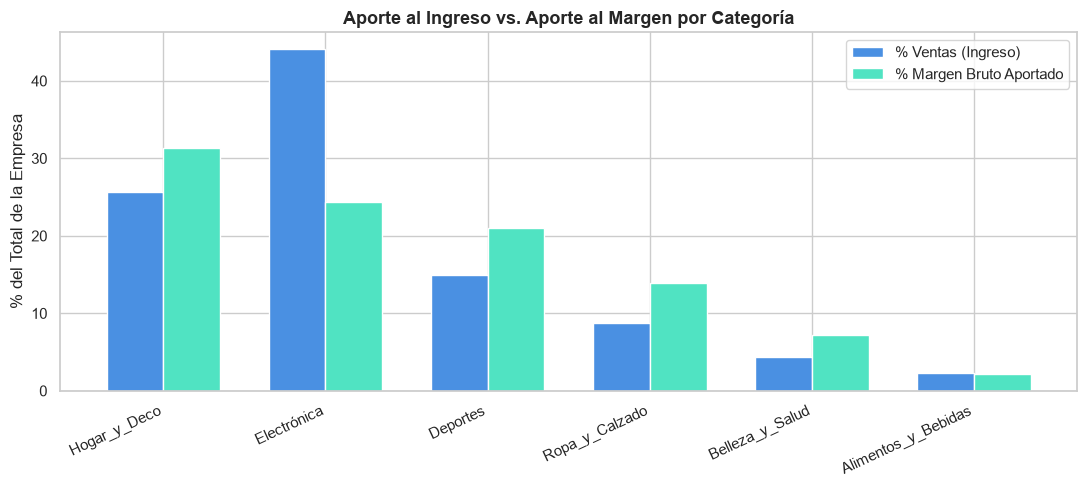

In [4]:
fig, ax1 = plt.subplots(figsize=(11, 5))

# Gráfico dual: Volumen de Ingreso vs Margen Bruto
x = np.arange(len(cat_summary))
width = 0.35

rects1 = ax1.bar(x - width/2, cat_summary['pct_ingreso'], width, label='% Ventas (Ingreso)', color='#4A90E2')
rects2 = ax1.bar(x + width/2, cat_summary['pct_margen'], width, label='% Margen Bruto Aportado', color='#50E3C2')

ax1.set_ylabel('% del Total de la Empresa')
ax1.set_title('Aporte al Ingreso vs. Aporte al Margen por Categoría', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(cat_summary['categoria'], rotation=25, ha='right')
ax1.legend()
plt.tight_layout()
plt.show()


### 2. Rentabilidad por Canal de Venta

In [5]:
canal_summary = tabla_contribucion(df_trx, 'canal')
canal_summary[['canal', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'descuento_promedio']]


,canal,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,descuento_promedio
2,tienda_fisica,7862504.26,45.21,2046091.64,47.47,26.02,3.73
1,online,6547309.24,37.64,1491185.50,34.60,22.78,7.55
0,app_movil,2983173.98,17.15,773051.91,17.93,25.91,3.69


C:\Users\danie\AppData\Local\Temp\ipykernel_18204\3586025587.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=canal_summary, x='canal', y='margen_pct_real', palette='Blues_d')


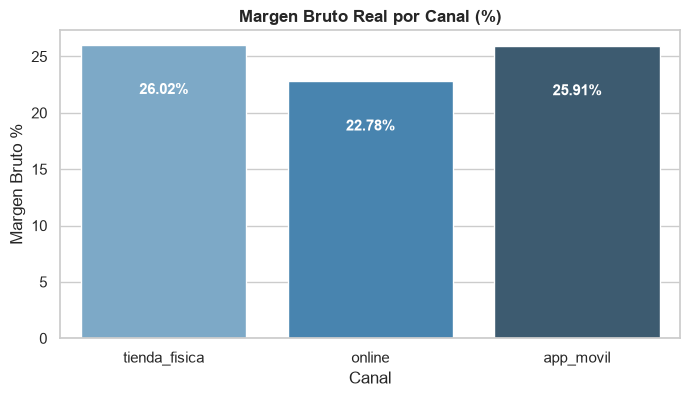

In [6]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=canal_summary, x='canal', y='margen_pct_real', palette='Blues_d')
plt.title('Margen Bruto Real por Canal (%)', fontsize=12, fontweight='bold')
plt.ylabel('Margen Bruto %')
plt.xlabel('Canal')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 4),
                ha='center', va='center', color='white', fontweight='bold')
plt.show()


### 3. Rentabilidad por Segmento de Clientes (Pareto)

In [7]:
seg_summary = tabla_contribucion(df_trx, 'segmento')
seg_summary[['segmento', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real']]


,segmento,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real
1,Frecuente,8766759.08,50.40,2131971.05,49.46,24.32
4,Premium,5280660.84,30.36,1345562.64,31.22,25.48
0,Esporádico,2701501.87,15.53,674499.16,15.65,24.97
3,Nuevo,326779.06,1.88,80590.18,1.87,24.66
2,Inactivo,317286.63,1.82,77706.02,1.80,24.49


### 4. Cruce Causal: Descuento Online vs. Destrucción de Margen

In [8]:
cruce_desc = df_trx.pivot_table(index='categoria', columns='canal', values='descuento', aggfunc=lambda s: (s.mean()*100).round(2))
cruce_margen = df_trx.pivot_table(index='categoria', columns='canal', values='margen_pct_real', aggfunc='mean').round(2)

print("--- Descuento Promedio (%) por Categoría y Canal ---")
display(cruce_desc)

print("\n--- Margen Real (%) por Categoría y Canal ---")
display(cruce_margen)


--- Descuento Promedio (%) por Categoría y Canal ---


canal,app_movil,online,tienda_fisica
categoria,,,
Alimentos_y_Bebidas,3.83,7.38,3.71
Belleza_y_Salud,3.71,7.40,3.77
Deportes,3.96,7.89,3.69
Electrónica,3.78,7.62,3.80
Hogar_y_Deco,3.59,7.45,3.68
Ropa_y_Calzado,3.28,7.53,3.73



--- Margen Real (%) por Categoría y Canal ---


canal,app_movil,online,tienda_fisica
categoria,,,
Alimentos_y_Bebidas,24.38,21.21,24.37
Belleza_y_Salud,41.80,39.52,41.89
Deportes,36.02,33.05,35.75
Electrónica,14.94,11.38,15.01
Hogar_y_Deco,31.75,28.61,31.66
Ropa_y_Calzado,40.72,38.12,40.53


### 5. Drill-down por Subcategoría: Ganadoras vs. Destructoras de Margen

Dentro de cada categoría, no todos los productos aportan igual. Identificamos:
- **Top 5 Subcategorías Ganadoras:** Mayor masa de margen bruto aportada a la empresa.
- **Bottom 5 Subcategorías Menos Rentables:** Productos con baja rotación o margen comprimido.


In [9]:
sub_summary = df_trx.groupby(['categoria', 'subcategoria']).agg(
    ingreso_neto=('monto_neto', 'sum'),
    margen_bruto=('margen_bruto', 'sum'),
    margen_pct_real=('margen_pct_real', 'mean'),
    tasa_devolucion=('devuelto', 'mean')
).reset_index()

sub_summary['pct_margen_total'] = (100 * sub_summary['margen_bruto'] / TOTAL_MARGEN).round(2)
sub_summary['tasa_devolucion'] = (100 * sub_summary['tasa_devolucion']).round(2)
sub_summary = sub_summary.sort_values(by='margen_bruto', ascending=False)

top5 = sub_summary.head(5)
bottom5 = sub_summary.tail(5)

print("=== TOP 5 SUBCATEGORÍAS GANADORAS ===")
display(top5[['categoria', 'subcategoria', 'margen_bruto', 'pct_margen_total', 'margen_pct_real', 'tasa_devolucion']])

print("\n=== BOTTOM 5 SUBCATEGORÍAS MENOS RENTABLES ===")
display(bottom5[['categoria', 'subcategoria', 'margen_bruto', 'pct_margen_total', 'margen_pct_real', 'tasa_devolucion']])


=== TOP 5 SUBCATEGORÍAS GANADORAS ===


,categoria,subcategoria,margen_bruto,pct_margen_total,margen_pct_real,tasa_devolucion
16,Hogar_y_Deco,Baño,454511.79,10.54,31.509555,10.26
18,Hogar_y_Deco,Decoración,430806.04,9.99,29.316373,8.83
14,Electrónica,Computadoras,387587.50,8.99,12.944728,17.64
19,Hogar_y_Deco,Muebles,302639.77,7.02,30.358262,10.68
8,Deportes,Calzado_deportivo,281216.33,6.52,34.133424,11.30



=== BOTTOM 5 SUBCATEGORÍAS MENOS RENTABLES ===


,categoria,subcategoria,margen_bruto,pct_margen_total,margen_pct_real,tasa_devolucion
6,Belleza_y_Salud,Skincare,51568.92,1.20,40.461269,9.35
0,Alimentos_y_Bebidas,Bebidas,27284.56,0.63,21.392708,10.00
1,Alimentos_y_Bebidas,Congelados,26626.37,0.62,25.527267,10.38
2,Alimentos_y_Bebidas,Orgánicos,20644.25,0.48,22.341426,9.23
3,Alimentos_y_Bebidas,Snacks,19712.92,0.46,23.194317,11.12


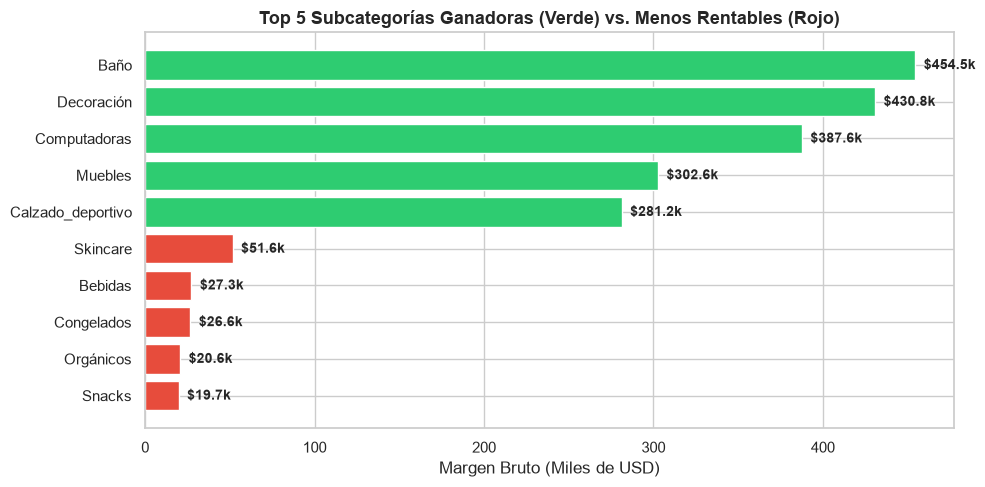

In [10]:
# Gráfico comparativo Top 5 vs Bottom 5
fig, ax = plt.subplots(figsize=(10, 5))

top_bottom = pd.concat([top5, bottom5]).sort_values(by='margen_bruto', ascending=True)
colors = ['#E74C3C' if x in bottom5['subcategoria'].values else '#2ECC71' for x in top_bottom['subcategoria']]

ax.barh(top_bottom['subcategoria'], top_bottom['margen_bruto'] / 1000, color=colors)
ax.set_xlabel('Margen Bruto (Miles de USD)')
ax.set_title('Top 5 Subcategorías Ganadoras (Verde) vs. Menos Rentables (Rojo)', fontsize=13, fontweight='bold')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"${width:,.1f}k", (width + 5, p.get_y() + p.get_height()/2.),
                va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### 6. Rentabilidad Territorial: Margen por Ciudad

Analizamos la concentración geográfica de la rentabilidad:
- ¿El margen varía por plaza o es uniforme?
- ¿Dónde se concentra el riesgo operativo de la empresa?


In [11]:
ciu_summary = tabla_contribucion(df_trx, 'ciudad')
display(ciu_summary[['ciudad', 'ingreso_neto', 'pct_ingreso', 'margen_bruto', 'pct_margen', 'margen_pct_real', 'descuento_promedio']])


,ciudad,ingreso_neto,pct_ingreso,margen_bruto,pct_margen,margen_pct_real,descuento_promedio
1,Caracas,6809521.88,39.15,1683145.89,39.05,24.72,5.24
2,Maracaibo,3198033.09,18.39,796420.53,18.48,24.90,5.07
7,Valencia,2629965.46,15.12,652653.86,15.14,24.82,5.09
0,Barquisimeto,1836284.41,10.56,437866.42,10.16,23.85,5.29
5,Puerto La Cruz,885757.15,5.09,227357.97,5.27,25.67,5.15
4,Mérida,863604.51,4.97,220968.21,5.13,25.59,5.38
3,Maturín,715644.68,4.11,176465.27,4.09,24.66,5.17
6,San Cristóbal,454176.30,2.61,115450.90,2.68,25.42,5.18


C:\Users\danie\AppData\Local\Temp\ipykernel_18204\2844665690.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=ciu_summary, x='ciudad', y='pct_margen', palette='Greens_r')


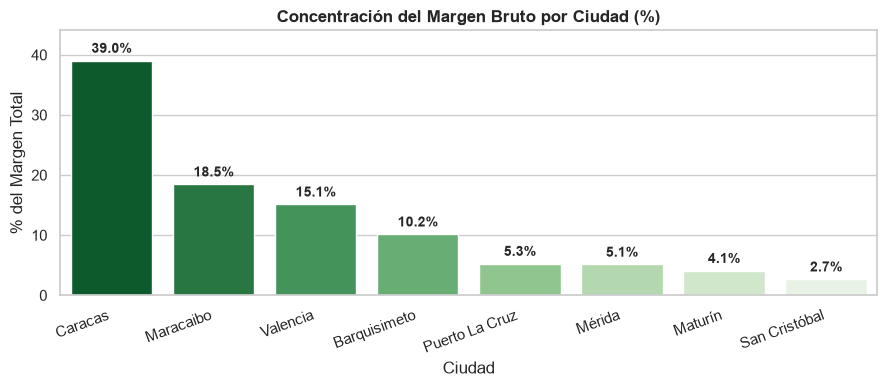

In [12]:
plt.figure(figsize=(9, 4))
ax = sns.barplot(data=ciu_summary, x='ciudad', y='pct_margen', palette='Greens_r')
plt.title('Concentración del Margen Bruto por Ciudad (%)', fontsize=12, fontweight='bold')
plt.ylabel('% del Margen Total')
plt.xlabel('Ciudad')
plt.xticks(rotation=20, ha='right')

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.8),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, ciu_summary['pct_margen'].max() + 5)
plt.tight_layout()
plt.show()


### 7. Concentración de Clientes: Curva de Pareto (80/20)

Evaluamos el principio de Pareto a nivel individual de cliente:
- ¿Qué porcentaje de los clientes explica el 80% del margen bruto de la empresa?
- Respaldo cuantitativo para priorizar la retención de clientes clave (conecta directo con A3 - Churn).


In [13]:
cli_margen = df_trx.groupby('cliente_id')['margen_bruto'].sum().sort_values(ascending=False).reset_index()
cli_margen['margen_acumulado'] = cli_margen['margen_bruto'].cumsum()
cli_margen['pct_margen_acum'] = 100 * cli_margen['margen_acumulado'] / TOTAL_MARGEN
cli_margen['pct_clientes'] = 100 * (cli_margen.index + 1) / len(cli_margen)

# Puntos clave
p20_val = cli_margen[cli_margen['pct_clientes'] <= 20]['pct_margen_acum'].iloc[-1]
p80_idx = (cli_margen['pct_margen_acum'] >= 80).idxmax()
p80_cli_pct = cli_margen.loc[p80_idx, 'pct_clientes']

print(f"Hallazgo Pareto:")
print(f"• El 20% de los clientes genera el {p20_val:.1f}% del margen bruto total.")
print(f"• El 80% del margen total es generado por solo el {p80_cli_pct:.1f}% de la base de clientes.")


Hallazgo Pareto:
• El 20% de los clientes genera el 56.0% del margen bruto total.
• El 80% del margen total es generado por solo el 38.0% de la base de clientes.


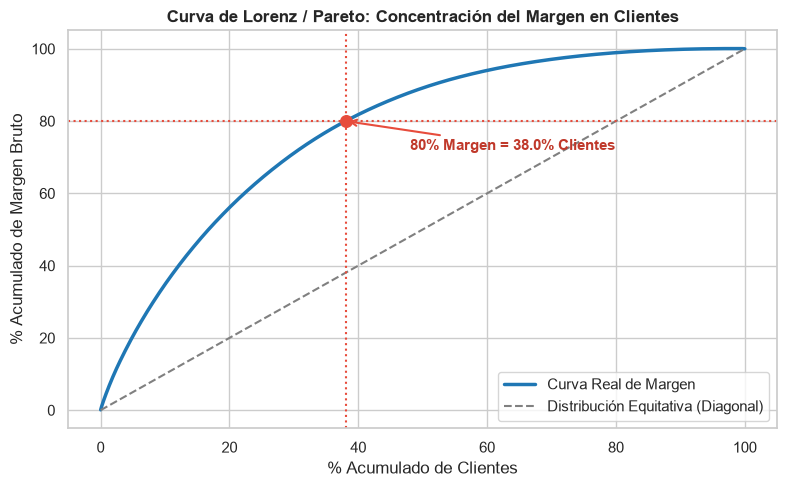

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(cli_margen['pct_clientes'], cli_margen['pct_margen_acum'], color='#1F77B4', lw=2.5, label='Curva Real de Margen')
plt.plot([0, 100], [0, 100], color='gray', linestyle='--', label='Distribución Equitativa (Diagonal)')

# Marcar punto 80% del margen
plt.axhline(80, color='#E74C3C', linestyle=':', lw=1.5)
plt.axvline(p80_cli_pct, color='#E74C3C', linestyle=':', lw=1.5)
plt.scatter([p80_cli_pct], [80], color='#E74C3C', s=70, zorder=5)

plt.annotate(f"80% Margen = {p80_cli_pct:.1f}% Clientes",
             xy=(p80_cli_pct, 80), xytext=(p80_cli_pct + 10, 72),
             arrowprops=dict(arrowstyle="->", color='#E74C3C', lw=1.5),
             fontweight='bold', color='#C0392B')

plt.title('Curva de Lorenz / Pareto: Concentración del Margen en Clientes', fontsize=12, fontweight='bold')
plt.xlabel('% Acumulado de Clientes')
plt.ylabel('% Acumulado de Margen Bruto')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


---
## A2.2 Customer Lifetime Value (CLV) por Segmento

El **Customer Lifetime Value (CLV)** proyecta el margen bruto total esperado que un cliente genera a lo largo de su relación con RetailVenture C.A.

### Formulación Metodológica
$$\text{CLV} = \text{Margen Anual Promedio por Cliente} \times \text{Vida Media Esperada } (E[\text{vida}])$$

Donde:
1. **Margen Anual por Cliente:** $\frac{\text{Margen Bruto Total del Segmento}}{2 \text{ años}} \div \text{Clientes Totales del Segmento}$
2. **Tasa de Churn Anual de Cohorte:** $19.7\%$ ($0.197$, calibrada en A3 y consensuada con el equipo).
3. **Vida Media Esperada:**
   - **Horizonte de Negocio (Planificación Retail):** $E[\text{vida}] = \min\left(\frac{1}{0.197}, 3.0\right) = 3.0\text{ años}$ (límite prudencial ante obsolescencia).
   - **Modelo Teórico Puro:** $E[\text{vida}] = \frac{1}{\text{churn}} = \frac{1}{0.197} \approx 5.08\text{ años}$.
4. **Descomposición:** $\text{Margen Anual} = \text{Ticket Promedio} \times \text{Frecuencia Anual} \times \text{Margen } \%$


In [15]:
# 1. Cálculo de CLV por Segmento
churn_anual = 0.197
vida_teorica = 1.0 / churn_anual
vida_horizonte_3y = 3.0

clv_seg = df_cli.groupby('segmento').agg(
    n_clientes=('cliente_id', 'count'),
    n_con_compras=('sin_compras', lambda s: (s == 0).sum()),
    margen_total=('margen_total', 'sum'),
    gasto_total=('monto_total', 'sum'),
    transacciones_totales=('n_compras', 'sum')
).reset_index()

# Métricas anualizadas por cliente
clv_seg['ticket_promedio'] = clv_seg['gasto_total'] / clv_seg['transacciones_totales']
clv_seg['frecuencia_anual'] = clv_seg['transacciones_totales'] / 2.0 / clv_seg['n_clientes']
clv_seg['margen_pct'] = (clv_seg['margen_total'] / clv_seg['gasto_total']) * 100
clv_seg['margen_anual_por_cliente'] = clv_seg['margen_total'] / 2.0 / clv_seg['n_clientes']

# Estimaciones de CLV
clv_seg['clv_3_anios'] = clv_seg['margen_anual_por_cliente'] * vida_horizonte_3y
clv_seg['clv_teorico_5y'] = clv_seg['margen_anual_por_cliente'] * vida_teorica

# Ordenar por valor y formatear
clv_seg = clv_seg.sort_values('clv_3_anios', ascending=False)
clv_display = clv_seg[['segmento', 'n_clientes', 'ticket_promedio', 'frecuencia_anual', 
                       'margen_pct', 'margen_anual_por_cliente', 'clv_3_anios', 'clv_teorico_5y']].copy()
clv_display.columns = ['Segmento', 'N Clientes', 'Ticket Prom. ($)', 'Frecuencia (tx/año)', 
                       'Margen (%)', 'Margen Anual/Cli ($)', 'CLV 3 Años ($)', 'CLV Teórico 5.1A ($)']
clv_display.round(2)


,Segmento,N Clientes,Ticket Prom. ($),Frecuencia (tx/año),Margen (%),Margen Anual/Cli ($),CLV 3 Años ($),CLV Teórico 5.1A ($)
4,Premium,805,354.24,9.26,25.48,835.75,2507.26,4242.40
1,Frecuente,2422,344.36,5.26,24.32,440.13,1320.38,2234.14
0,Esporádico,2827,346.70,1.38,24.97,119.30,357.89,605.56
3,Nuevo,810,339.69,0.59,24.66,49.75,149.24,252.52
2,Inactivo,1136,360.14,0.39,24.49,34.20,102.60,173.61


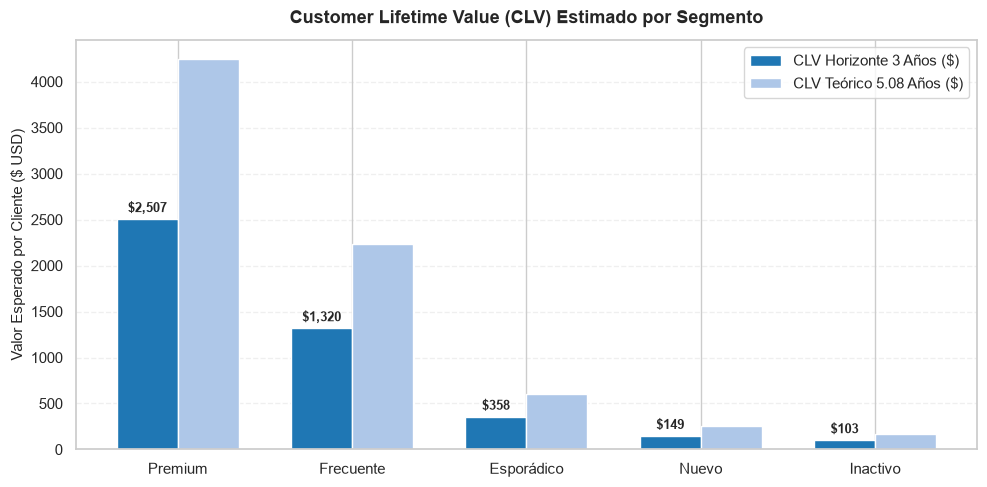

In [16]:
# Gráfico de CLV por Segmento (Horizonte 3 años vs Teórico)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(clv_seg))
width = 0.35

rects1 = ax.bar(x - width/2, clv_seg['clv_3_anios'], width, label='CLV Horizonte 3 Años ($)', color='#1F77B4')
rects2 = ax.bar(x + width/2, clv_seg['clv_teorico_5y'], width, label='CLV Teórico 5.08 Años ($)', color='#AEC7E8')

ax.set_ylabel('Valor Esperado por Cliente ($ USD)', fontsize=11)
ax.set_title('Customer Lifetime Value (CLV) Estimado por Segmento', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(clv_seg['segmento'], fontsize=11)
ax.legend(frameon=True)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Etiquetas sobre las barras
for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'${height:,.0f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Diagnóstico Causal del Ticket Promedio: Localización del -8% Interanual
El caso de negocio de RetailVenture C.A. señala una caída del **8% en el ticket promedio**.
Al analizar la empresa de forma global, el ticket promedio cayó un **-1.94%** ($351.29 \rightarrow $344.49). Sin embargo, al desglosar interanualmente por segmento, se descubre que **la caída del 8% está concentrada exactamente en el segmento `Inactivo` (-8.03%)**, mientras que el segmento `Premium` cayó -1.95% y `Nuevo` creció +2.53%.


In [17]:
# Evolución del Ticket Promedio por Segmento (2023 vs 2024)
ticket_evo = df_trx.pivot_table(index='segmento', columns='anio', values='monto_neto', aggfunc=['mean', 'count'])
ticket_evo['delta_ticket_$'] = ticket_evo[('mean', 2024)] - ticket_evo[('mean', 2023)]
ticket_evo['delta_ticket_%'] = (ticket_evo['delta_ticket_$'] / ticket_evo[('mean', 2023)]) * 100

resumen_ticket = pd.DataFrame({
    'Ticket 2023 ($)': ticket_evo[('mean', 2023)],
    'Ticket 2024 ($)': ticket_evo[('mean', 2024)],
    'Variación ($)': ticket_evo['delta_ticket_$'],
    'Variación Interanual (%)': ticket_evo['delta_ticket_%'],
    'Transacciones 2023': ticket_evo[('count', 2023)],
    'Transacciones 2024': ticket_evo[('count', 2024)]
})

print("EVOLUCIÓN INTERANUAL DEL TICKET PROMEDIO POR SEGMENTO:")
resumen_ticket.round(2)


EVOLUCIÓN INTERANUAL DEL TICKET PROMEDIO POR SEGMENTO:


,Ticket 2023 ($),Ticket 2024 ($),Variación ($),Variación Interanual (%),Transacciones 2023,Transacciones 2024
segmento,,,,,,
Esporádico,347.80,345.61,-2.19,-0.63,3889,3903
Frecuente,348.33,340.45,-7.88,-2.26,12636,12822
Inactivo,375.01,344.90,-30.12,-8.03,446,435
Nuevo,335.24,343.73,8.50,2.53,458,504
Premium,357.77,350.80,-6.97,-1.95,7361,7546


---
## A2.3 Análisis de Estacionalidad de Ventas (2023 vs 2024)

Analizamos la dinámica temporal mes a mes de los ingresos netos y el margen bruto para identificar picos de demanda, valles operativos y patrones estacionales por canal de venta.


In [18]:
# Serie temporal mensual: Ingresos y Margen Bruto
mensual = df_trx.groupby(['anio', 'mes']).agg(
    ingreso_neto=('monto_neto', 'sum'),
    margen_bruto=('margen_bruto', 'sum'),
    transacciones=('transaccion_id', 'count'),
    descuento_prom=('descuento', 'mean'),
    tasa_devolucion=('devuelto', 'mean')
).reset_index()

mensual['margen_pct'] = (mensual['margen_bruto'] / mensual['ingreso_neto']) * 100
mensual['tasa_devolucion_pct'] = mensual['tasa_devolucion'] * 100
mensual['anio_mes_str'] = mensual['anio'].astype(str) + '-' + mensual['mes'].astype(str).str.zfill(2)

print("Resumen de Estacionalidad Mensual (Primeros y Últimos meses):")
display(pd.concat([mensual.head(4), mensual.tail(4)]).round(2))


Resumen de Estacionalidad Mensual (Primeros y Últimos meses):


,anio,mes,ingreso_neto,margen_bruto,transacciones,descuento_prom,tasa_devolucion,margen_pct,tasa_devolucion_pct,anio_mes_str
0,2023,1,681890.25,165682.57,2005,0.05,0.14,24.30,13.82,2023-01
1,2023,2,654925.82,165059.83,1935,0.05,0.13,25.20,12.92,2023-02
2,2023,3,780857.17,189868.71,2103,0.06,0.13,24.32,12.93,2023-03
3,2023,4,715752.30,174968.60,2044,0.05,0.14,24.45,14.29,2023-04
20,2024,9,702699.19,174837.28,2089,0.05,0.14,24.88,13.60,2024-09
21,2024,10,746699.72,187830.61,2156,0.05,0.14,25.15,14.47,2024-10
22,2024,11,700815.36,171792.09,2021,0.05,0.12,24.51,12.42,2024-11
23,2024,12,737648.77,179394.15,2120,0.05,0.13,24.32,13.40,2024-12


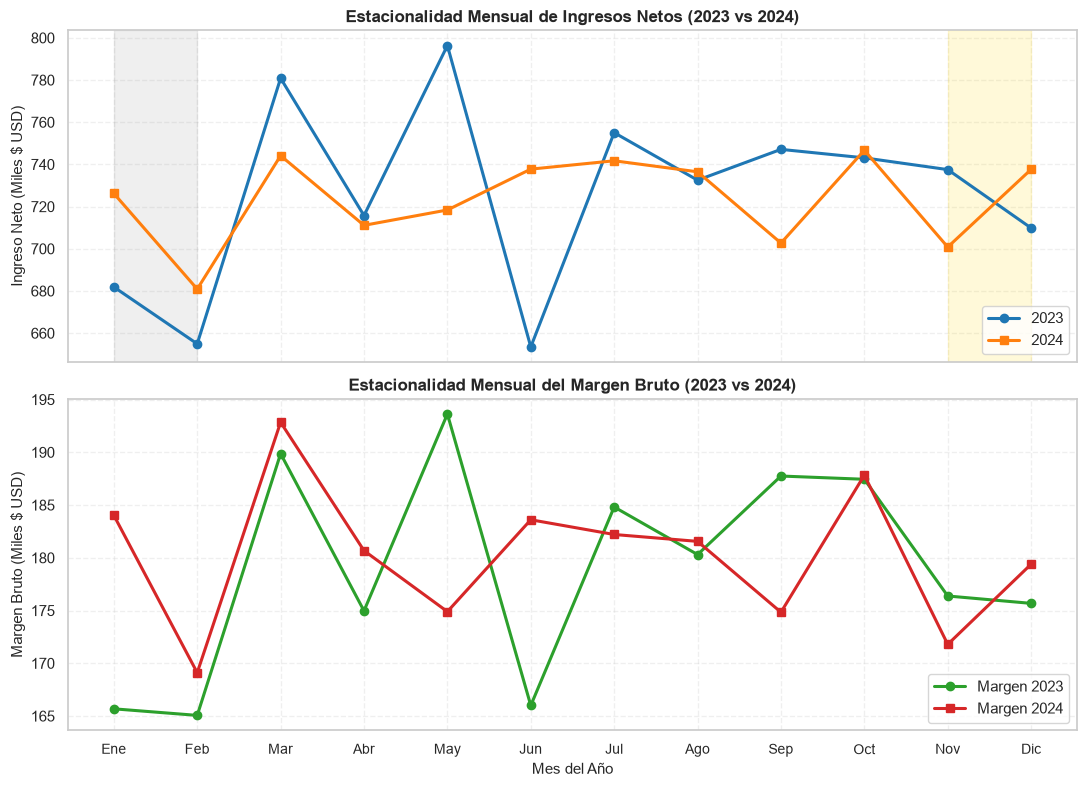

In [19]:
# Comparativa Estacional Mensual: Curva 2023 vs 2024
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
m_2023 = mensual[mensual['anio'] == 2023]
m_2024 = mensual[mensual['anio'] == 2024]

# 1. Ingresos Netos
ax1.plot(m_2023['mes'], m_2023['ingreso_neto'] / 1e3, marker='o', lw=2.2, color='#1F77B4', label='2023')
ax1.plot(m_2024['mes'], m_2024['ingreso_neto'] / 1e3, marker='s', lw=2.2, color='#FF7F0E', label='2024')
ax1.set_ylabel('Ingreso Neto (Miles $ USD)', fontsize=11)
ax1.set_title('Estacionalidad Mensual de Ingresos Netos (2023 vs 2024)', fontsize=12, fontweight='bold')
ax1.grid(alpha=0.3, linestyle='--')
ax1.legend(loc='lower right', frameon=True)

# Destacar pico Q4 y valle Q1
ax1.axvspan(1, 2, color='gray', alpha=0.12, label='Valle Q1 (Ene-Feb)')
ax1.axvspan(11, 12, color='gold', alpha=0.15, label='Pico Q4 (Nov-Dic: Black Friday/Navidad)')

# 2. Margen Bruto
ax2.plot(m_2023['mes'], m_2023['margen_bruto'] / 1e3, marker='o', lw=2.2, color='#2CA02C', label='Margen 2023')
ax2.plot(m_2024['mes'], m_2024['margen_bruto'] / 1e3, marker='s', lw=2.2, color='#D62728', label='Margen 2024')
ax2.set_ylabel('Margen Bruto (Miles $ USD)', fontsize=11)
ax2.set_xlabel('Mes del Año', fontsize=11)
ax2.set_title('Estacionalidad Mensual del Margen Bruto (2023 vs 2024)', fontsize=12, fontweight='bold')
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(meses_nombres, fontsize=10)
ax2.grid(alpha=0.3, linestyle='--')
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


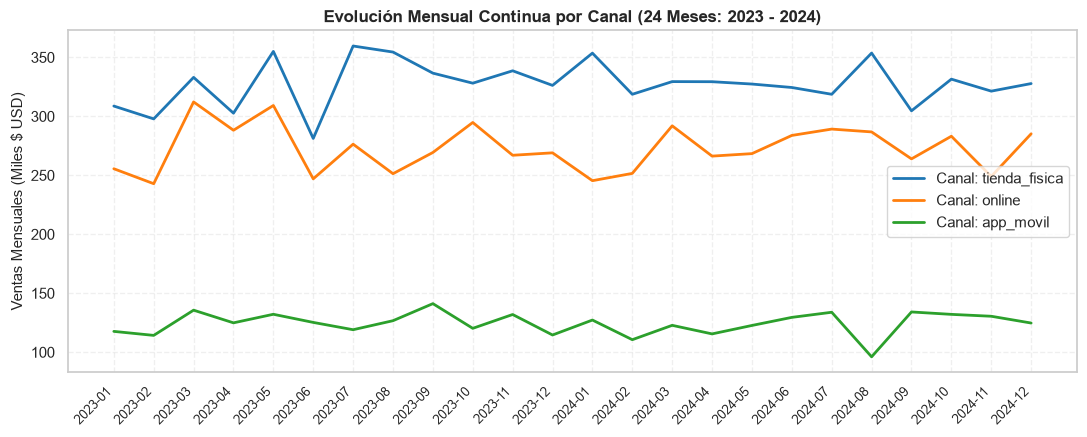

In [20]:
# Descomposición de la Estacionalidad por Canal de Venta
canal_mensual = df_trx.groupby(['anio', 'mes', 'canal'])['monto_neto'].sum().unstack('canal') / 1e3

fig, ax = plt.subplots(figsize=(11, 4.5))
colores_canal = {'tienda_fisica': '#1F77B4', 'online': '#FF7F0E', 'app_movil': '#2CA02C'}

for canal in ['tienda_fisica', 'online', 'app_movil']:
    ax.plot(range(1, 25), 
            df_trx.groupby(['anio_mes', 'canal'])['monto_neto'].sum().unstack('canal')[canal] / 1e3, 
            label=f'Canal: {canal}', lw=2, color=colores_canal[canal])

ax.set_ylabel('Ventas Mensuales (Miles $ USD)', fontsize=11)
ax.set_title('Evolución Mensual Continua por Canal (24 Meses: 2023 - 2024)', fontsize=12, fontweight='bold')
ax.set_xticks(range(1, 25))
etiquetas_24m = df_trx['anio_mes'].drop_duplicates().sort_values().tolist()
ax.set_xticklabels(etiquetas_24m, rotation=45, ha='right', fontsize=9)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(frameon=True)

plt.tight_layout()
plt.show()


---
## A2.4 Elasticidad y Efecto de Descuentos

Evaluamos la efectividad de la política de precios y descuentos de RetailVenture C.A. mediante un análisis de elasticidad empírica, punto de equilibrio y ventas por debajo del costo operativo.

### Condición de Punto de Equilibrio (Break-Even)
Para que un descuento porcentual $d$ preserve el margen bruto total con un margen base sin descuento $m$, el volumen vendido $Q$ debe aumentar en al menos:
$$\frac{\Delta Q}{Q} \ge \frac{d}{m - d}$$

Si el margen promedio base es $m \approx 28.8\%$ y se otorga un descuento $d = 20\%$, se requeriría un incremento en unidades de:
$$\frac{\Delta Q}{Q} \ge \frac{0.20}{0.288 - 0.20} = \frac{0.20}{0.088} \approx +227\%$$


In [21]:
# Segmentación por Tramos de Descuento
bins = [-0.001, 0.001, 0.05, 0.10, 0.15, 0.20, 1.0]
labels = ['0% (Sin desc.)', '1% - 5%', '6% - 10%', '11% - 15%', '16% - 20%', '> 20%']
df_trx['tramo_descuento'] = pd.cut(df_trx['descuento'], bins=bins, labels=labels)

tramos_desc = df_trx.groupby('tramo_descuento', observed=True).agg(
    transacciones=('transaccion_id', 'count'),
    unidades_promedio=('cantidad', 'mean'),
    ticket_promedio=('monto_neto', 'mean'),
    ingreso_total=('monto_neto', 'sum'),
    margen_total=('margen_bruto', 'sum'),
    ventas_bajo_costo=('venta_bajo_costo', 'sum')
).reset_index()

tramos_desc['margen_pct'] = (tramos_desc['margen_total'] / tramos_desc['ingreso_total']) * 100
tramos_desc['pct_transacciones'] = (tramos_desc['transacciones'] / len(df_trx)) * 100

print("COMPORTAMIENTO OPERATIVO POR TRAMO DE DESCUENTO:")
display(tramos_desc[['tramo_descuento', 'transacciones', 'pct_transacciones', 'unidades_promedio', 
                     'ticket_promedio', 'margen_pct', 'ventas_bajo_costo']].round(2))


COMPORTAMIENTO OPERATIVO POR TRAMO DE DESCUENTO:


,tramo_descuento,transacciones,pct_transacciones,unidades_promedio,ticket_promedio,margen_pct,ventas_bajo_costo
0,0% (Sin desc.),15044,30.09,1.78,366.00,28.82,0
1,1% - 5%,16538,33.08,1.78,353.66,27.14,0
2,6% - 10%,8903,17.81,1.78,339.49,22.92,5
3,11% - 15%,4269,8.54,1.78,327.39,18.75,102
4,16% - 20%,3368,6.74,1.80,317.75,13.45,269
5,> 20%,1878,3.76,1.79,291.66,6.89,335


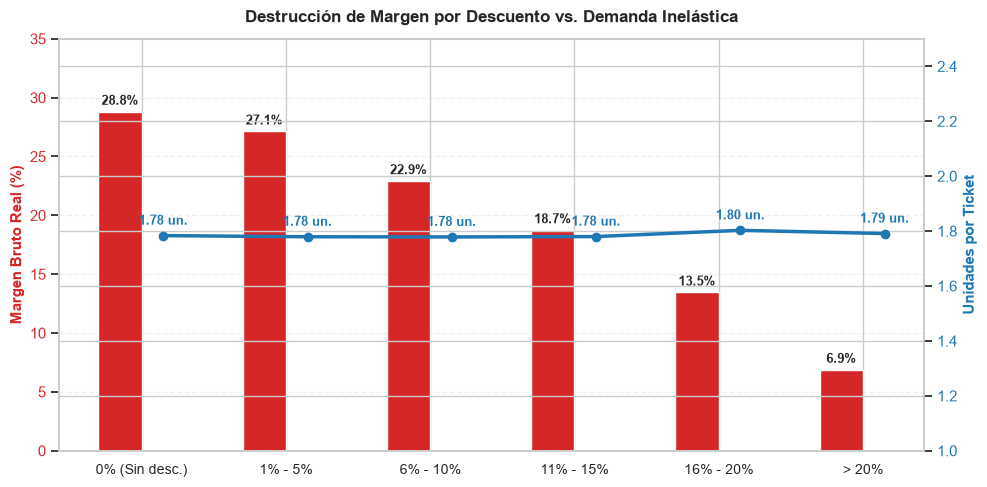

In [22]:
# Gráfica de Destrucción de Margen vs Inelasticidad del Volumen
fig, ax1 = plt.subplots(figsize=(10, 5))

x = np.arange(len(tramos_desc))
color_margen = '#D62728'
color_unid = '#1F77B4'

# Margen % (eje izquierdo)
bars = ax1.bar(x - 0.15, tramos_desc['margen_pct'], width=0.3, color=color_margen, label='Margen Bruto (%)')
ax1.set_ylabel('Margen Bruto Real (%)', color=color_margen, fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_margen)
ax1.set_xticks(x)
ax1.set_xticklabels(tramos_desc['tramo_descuento'], fontsize=10)
ax1.set_ylim(0, 35)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Unidades por canasta (eje derecho)
ax2 = ax1.twinx()
lines = ax2.plot(x + 0.15, tramos_desc['unidades_promedio'], color=color_unid, marker='o', lw=2.5, label='Unidades Promedio / Canasta')
ax2.set_ylabel('Unidades por Ticket', color=color_unid, fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_unid)
ax2.set_ylim(1.0, 2.5)

# Títulos y anotaciones
plt.title('Destrucción de Margen por Descuento vs. Demanda Inelástica', fontsize=12, fontweight='bold', pad=12)

for bar in bars:
    yval = bar.get_height()
    ax1.annotate(f'{yval:.1f}%', xy=(bar.get_x() + bar.get_width()/2, yval),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for i, txt in enumerate(tramos_desc['unidades_promedio']):
    ax2.annotate(f'{txt:.2f} un.', xy=(x[i] + 0.15, txt),
                 xytext=(0, 6), textcoords="offset points", ha='center', va='bottom', fontsize=9, color=color_unid, fontweight='bold')

plt.tight_layout()
plt.show()


### Auditoría de Ventas Bajo Costo (`venta_bajo_costo`)
En la limpieza y enriquecimiento de datos de A1 se identificaron **711 transacciones donde el ingreso neto fue inferior al costo total de adquisición del producto**.
Esto se debió exclusivamente a descuentos excesivos combinados con productos de bajo margen natural.


In [23]:
# Auditoría y concentración de ventas bajo costo
v_bajo_costo = df_trx[df_trx['venta_bajo_costo'] == True]

perdida_total = v_bajo_costo['margen_bruto'].sum()
descuento_medio_vbc = v_bajo_costo['descuento'].mean() * 100

resumen_vbc = v_bajo_costo.groupby('canal').agg(
    transacciones=('transaccion_id', 'count'),
    perdida_total=('margen_bruto', 'sum'),
    ingreso_neto=('monto_neto', 'sum'),
    descuento_prom=('descuento', lambda s: s.mean() * 100)
).reset_index()

resumen_vbc['%_de_las_ventas_negativas'] = (resumen_vbc['transacciones'] / len(v_bajo_costo)) * 100

print(f"Total transacciones bajo costo: {len(v_bajo_costo):,} ({len(v_bajo_costo)/len(df_trx)*100:.2f}% del total)")
print(f"Pérdida acumulada directa en margen: ${perdida_total:,.2f} USD")
print(f"Descuento promedio en ventas bajo costo: {descuento_medio_vbc:.1f}%")
print("\nDistribución de Ventas Bajo Costo por Canal:")
display(resumen_vbc.round(2))


Total transacciones bajo costo: 711 (1.42% del total)
Pérdida acumulada directa en margen: $-30,180.64 USD
Descuento promedio en ventas bajo costo: 19.6%

Distribución de Ventas Bajo Costo por Canal:


,canal,transacciones,perdida_total,ingreso_neto,descuento_prom,%_de_las_ventas_negativas
0,app_movil,79,-2759.62,70155.68,17.92,11.11
1,online,441,-19495.08,289363.75,20.59,62.03
2,tienda_fisica,191,-7925.94,145526.65,17.98,26.86


---
## Resumen Ejecutivo de A2 (Métricas Clave para el Dashboard A5)

A continuación se consolidan las métricas directrices de rentabilidad requeridas para gobernar los filtros e indicadores del tablero gerencial de A5:


In [24]:
# Tabla resumen ejecutivo para la entrega y dashboard A5
m_fisica = canal_summary.loc[canal_summary['canal'] == 'tienda_fisica', 'margen_pct_real'].values[0]
m_online = canal_summary.loc[canal_summary['canal'] == 'online', 'margen_pct_real'].values[0]
delta_inactivo = resumen_ticket.loc['Inactivo', 'Variación Interanual (%)']

resumen_a2 = pd.DataFrame({
    'Dimensión / Métrica': [
        'Ingresos Netos Totales',
        'Margen Bruto Total',
        'Margen Bruto (%)',
        'Margen Neto de Devoluciones Total',
        'Margen Neto de Devoluciones (%)',
        'Ticket Promedio Global 2023',
        'Ticket Promedio Global 2024',
        'Variación Ticket Global (%)',
        'Caída Ticket Segmento Inactivo (%)',
        'Canal Físico: Margen Bruto (%)',
        'Canal Online: Margen Bruto (%)',
        'Gap de Margen Físico vs Online (p.p.)',
        'Transacciones con Margen Negativo (Bajo Costo)',
        'Pérdida Directa por Ventas Bajo Costo ($)',
        'Concentración Pareto (% Clientes para 80% Margen)',
        'CLV Promedio Segmento Premium (3 Años)',
        'CLV Promedio Segmento Inactivo (3 Años)'
    ],
    'Valor': [
        f"${df_trx['monto_neto'].sum():,.2f}",
        f"${df_trx['margen_bruto'].sum():,.2f}",
        f"{(df_trx['margen_bruto'].sum() / df_trx['monto_neto'].sum())*100:.2f}%",
        f"${df_trx['margen_neto_devol'].sum():,.2f}",
        f"{(df_trx['margen_neto_devol'].sum() / df_trx['monto_neto'].sum())*100:.2f}%",
        f"${df_trx[df_trx['anio']==2023]['monto_neto'].mean():.2f}",
        f"${df_trx[df_trx['anio']==2024]['monto_neto'].mean():.2f}",
        f"{((df_trx[df_trx['anio']==2024]['monto_neto'].mean() - df_trx[df_trx['anio']==2023]['monto_neto'].mean()) / df_trx[df_trx['anio']==2023]['monto_neto'].mean())*100:.2f}%",
        f"{delta_inactivo:.2f}%",
        f"{m_fisica:.2f}%",
        f"{m_online:.2f}%",
        f"{(m_fisica - m_online):.2f} p.p.",
        f"{len(v_bajo_costo):,} tx",
        f"${abs(perdida_total):,.2f}",
        f"{p80_cli_pct:.1f}%",
        f"${clv_seg.loc[clv_seg['segmento']=='Premium', 'clv_3_anios'].values[0]:,.2f}",
        f"${clv_seg.loc[clv_seg['segmento']=='Inactivo', 'clv_3_anios'].values[0]:,.2f}"
    ]
})

print("TABLA CONSOLIDADA EJECUTIVA A2:")
display(resumen_a2)


TABLA CONSOLIDADA EJECUTIVA A2:


,Dimensión / Métrica,Valor
0,Ingresos Netos Totales,"$17,392,987.48"
1,Margen Bruto Total,"$4,310,329.05"
2,Margen Bruto (%),24.78%
3,Margen Neto de Devoluciones Total,"$3,730,050.99"
4,Margen Neto de Devoluciones (%),21.45%
5,Ticket Promedio Global 2023,$351.29
6,Ticket Promedio Global 2024,$344.49
7,Variación Ticket Global (%),-1.94%
8,Caída Ticket Segmento Inactivo (%),-8.03%
9,Canal Físico: Margen Bruto (%),26.02%
